# The MCCD guide: how a death certificate works, and how this pipeline writes one

This notebook teaches the domain and the code together. You will follow one record, S01, from a
clinical narrative to a coded certificate, and run each function of the pipeline on it yourself.
Where a function behaves differently in different situations, you will see those situations one at
a time, with the outcome stated before the cell runs, so you can check your understanding against
the output.

The order is the order the domain has:

1. What a death certificate is, and why the order of Part I matters.
2. The underlying cause of death, and how the WHO's cause selector picks it.
3. Why free text fails: uninformative causes and invented evidence.
4. Step 1. Draft: the model writes a certificate.
5. Step 2. Check: the rules, the WHO coding, and the two fixes.
6. Step 3. Decide: the route and its reasons, then the whole pipeline at once.
7. The routes, and what a reviewer does with them.
8. How we measure whether any of this works.

Take your time with sections 1 to 3 even if you came for the code. Every rule in Step 2 and every
reason code in Step 3 exists because of something in those sections.

The cells call the live model and the WHO ICD-API container, so run `uv run automccd-lite icd start`
first (or `uv run automccd-lite serve`, which starts it too).


In [1]:
import copy, json
from _helpers import *
from automccd_lite.config import settings
from automccd_lite.coding import code_terms, fix_terms, low_score_terms, scoped_to_terms
from automccd_lite.decide import as_response, decide
from automccd_lite.draft import build_prompt, draft_certificate, system_prompt
from automccd_lite.eval import chain_to_cert, load_cases, load_reference, reference_to_cert
from automccd_lite.models import Draft
from automccd_lite.pipeline import build_deps, certify_record
from automccd_lite.rules import apply_rules, check_rules, fix_rules

cfg = settings()
deps = build_deps(cfg)  # the model call, the WHO client and the autocode cache
ask, who, cache = deps.ask, deps.who, deps.cache
record = load_record("S01")
assert who.available(), "the WHO ICD-API container is not up; run `uv run automccd-lite icd start`"
print("model:", cfg.draft.model, "| ICD release:", cfg.check.icd_release, "| record:", record.record_id)

model: gpt-5-nano-2025-08-07 | ICD release: 2026-01 | record: S01


## 1. What a death certificate is

When someone dies, a doctor fills in a Medical Certificate of Cause of Death (MCCD). The WHO
publishes an international form so that every country records deaths the same way, and the
statistics built from those forms (which diseases kill people, at what ages, where) rest on one
field above all others: the **underlying cause of death (UCOD)**. That is the disease or injury
that started the chain of events leading to death. Not the last event, the first.

The form captures that chain in **Part I**, which you read from the bottom up:

- **Line 1a** is the immediate cause, what the person actually died of.
- **Line 1b** is what caused 1a. **Line 1c** is what caused 1b, and so on, down to 1d.
- The lowest line you use is the originating condition, and that is the underlying cause.

Each line carries an **interval**: how long before death that condition began. Because each line
causes the one above it, intervals cannot shrink as you go down. A condition that started two days
ago cannot have caused one that started five years ago.

**Part II** holds other significant conditions that contributed to the death but were not part of
that causal chain: a diabetes that weakened the patient, say, but did not start the sequence.

Below is the certificate the client's teaching material gives as the answer for S01: the
reference certificate (gold). Read the narrative again (section 1 of the how-to guide shows it),
then read this form from the bottom up: meningitis, which became sepsis, which became septic shock,
which killed the patient. Diabetes and the transplant contributed but sit in Part II.


In [2]:
reference = load_reference("S01")
ref_cert = reference_to_cert(reference)
render_mccd(ref_cert, title="S01: the client's answer (reference certificate)")

### Why the order matters

Suppose a doctor writes the same three conditions in the opposite order: meningitis on 1a, septic
shock on the bottom line. Every word is still true, and the patient still had all three. But the
certificate now claims that shock caused the meningitis, and the statistics would count this as a
death from shock, a symptom, not from a bacterial infection, a preventable cause. Public health
programmes are planned on those counts. The order is the medicine.

You will see that difference measured in the next section.


## 2. The underlying cause, and how the WHO's cause selector picks it

A certificate is free text. Statistics need codes. The WHO's **ICD-11** is the classification that
gives every disease a code (`1D01.0` is Staphylococcus aureus meningitis), and the WHO ships a
container, the **ICD-API**, with three tools we use:

- **The term coder (autocode)** turns a written diagnosis into the closest ICD-11 code, with a
  match score between 0 and 1 that says how sure it is.
- **The cause selector (DORIS)** reads the coded certificate and selects the underlying cause.
  Usually that is the lowest line, but DORIS applies the WHO's selection rules on top: some
  conditions cannot be an underlying cause and DORIS moves past them, some sequences are
  implausible and DORIS rejects them. It returns the code it chose and a report of its rules.
- **The quality checks (CoDEdit)** return issue ids. `FER-CE-931` is the one we care most about:
  the underlying cause is **ill-defined**, meaning the certificate tells the statistician nothing.

The function `code_terms` runs all three on a certificate. Here it codes the reference
certificate. What to look for: each Part I term gets a code and a score of 1.0, because the
reference uses standard names; DORIS's `ucod_stem_code` is the meningitis line's code, the lowest
line; and the DORIS report walks you through the rule it applied. One surprise to expect: CoDEdit
raises a `BER-CE-1` remark. "Renal transplant" in Part II autocodes to an injury-chapter code that
wants an external cause, and DORIS invents a default one. That is a quirk of the WHO tooling on
this record, and it is also why S01 almost never routes `auto` through this pipeline: a CoDEdit
remark is a reason for review.


In [3]:
coded_ref = code_terms(ref_cert, cache, who, record.demographics)
print("codes per Part I line :", coded_ref.codes["part1"])
print("autocode match scores :", coded_ref.match_scores)
print("DORIS underlying cause:", coded_ref.doris["ucod_stem_code"], "(full:", coded_ref.doris["ucod_code"], ")")
print("CoDEdit issues        :", coded_ref.codedit["issue_ids"] or "none")
print()
print("DORIS report:")
print(coded_ref.doris["report"])

codes per Part I line : ['1G41', '1B5Z', '1B54']
autocode match scores : [1.0, 1.0, 1.0]
DORIS underlying cause: 1B54 (full: 1B54/1G41 )
CoDEdit issues        : ['BER-CE-1']

DORIS report:
The following conditions - NE84 - were reported without an external cause, a default external cause code - NE84>NE84/PB6Z - has been assigned. Manual check of the UCOD is needed, compliant with local and national rules and regulations. 
The external cause (PB6Z) has been placed at the beginning of the cluster, followed by the injury (NE84).
SP3: 1B54 is the first condition on the lowest used line causing all entries above, and is selected as the tentative starting point (TSP).
1G41 are manifestations of the selected underlying cause of death 1B54 and it is added as a postcoordination - 1B54>1B54/1G41.


Full report:
The following conditions - NE84 - were reported without an external cause, a default external cause code - NE84>NE84/PB6Z - has been assigned. Manual check of the UCOD is needed, complian

### The same conditions, reversed

Now the experiment from section 1. The cell reverses Part I so that septic shock sits on the bottom
line. Expected outcome: the codes per line are the same codes in the opposite order. DORIS's
selection rules know that meningitis causes sepsis and sepsis causes shock, so this time it still
finds its way back to the meningitis; but read the warning and the CoDEdit list: a new `BER-CE-22`
says the sequence as written is not acceptable. The WHO rules rescued this certificate because the
three conditions are medically linked. Write two unrelated conditions in the wrong order and no rule
will rescue you: the wrong one becomes the underlying cause, silently.


In [4]:
reversed_cert = copy.deepcopy(ref_cert)
reversed_cert["part1"] = list(reversed(reversed_cert["part1"]))
coded_rev = code_terms(reversed_cert, cache, who, record.demographics)
print("codes per Part I line :", coded_rev.codes["part1"])
print("DORIS underlying cause:", coded_rev.doris["ucod_stem_code"], " (was", coded_ref.doris["ucod_stem_code"], "in the right order)")
print("DORIS warning         :", coded_rev.doris.get("warning"))
print("CoDEdit issues        :", coded_rev.codedit["issue_ids"] or "none")

codes per Part I line : ['1B54', '1B5Z', '1G41']
DORIS underlying cause: 1B54  (was 1B54 in the right order)
DORIS warning         : The following conditions - NE84 - were reported without an external cause, a default external cause code - NE84>NE84/PB6Z - has been assigned. Manual check of the UCOD is needed, compliant with local and national rules and regulations.
External cause or injury is mentioned - PB6Z/NE84 - but is not the tentative underlying cause - 1B54.
The postcoordinations - 1G41 - were selected from conditions that are potential manifestations of the tentative underlying cause - 1B54, manual check of their validity is needed.

CoDEdit issues        : ['BER-CE-1', 'BER-CE-22']


## 3. Why free text fails

Two things go wrong when a certificate is written carelessly, by a tired doctor or by a language
model, and both are invisible to a reader who does not know the rules.

**Uninformative causes.** "Cardiac arrest", "respiratory failure", "multi-organ failure" are modes
of dying: every death ends in the heart stopping. A certificate whose underlying cause (UCOD) is
one of these says nothing about why the person died. The WHO calls these ill-defined, the quality
checks (CoDEdit) flag them with `FER-CE-931`, and our rule 2 (mode of dying) refuses them on any
Part I line before coding even starts.

Expected outcome below: a certificate consisting of "Cardiac arrest" alone codes fine (autocode
finds a code for it), DORIS selects it, and CoDEdit's ill-defined flag is **true**. Coding does not
catch the problem; only the quality check does, which is why we run CoDEdit a second time on the
selected underlying cause alone (`codedit_cause`).


In [5]:
arrest = chain_to_cert(["Cardiac arrest"])
coded_arrest = code_terms(arrest, cache, who, record.demographics)
print("code                  :", coded_arrest.codes["part1"], "score", coded_arrest.match_scores)
print("DORIS underlying cause:", coded_arrest.doris["ucod_stem_code"])
print("CoDEdit on the cause  :", coded_arrest.codedit_cause["issue_ids"], "ill_defined =", coded_arrest.codedit_cause["ill_defined"])

code                  : ['MC82.Z'] score [1.0]
DORIS underlying cause: MC82.Z
CoDEdit on the cause  : ['FER-CE-931'] ill_defined = True


**Invented evidence.** A language model asked to write a certificate will write a plausible one.
Plausible is the problem: it can name a diagnosis the record never mentions, and nothing in the
output reveals that. So our prompt requires the model to quote, for every line, the exact words of
the record that support it (`evidence_span`) and name the note they came from (`evidence_field`).
Rule 1 (exact quote) then checks each quote mechanically. A model that invents a diagnosis has to
invent a quote too, and the quote is checkable even when the medicine is not.

This is the single most important idea in the pipeline: **the model proposes, the code checks, and
only what the code could check may go through without a human.** Keep it in mind through the three
steps.

```
Step 1. Draft    draft_certificate
Step 2. Check    check_rules -> fix_rules (once, when a rule breaks)
                 fix_terms (once, when a term codes weakly) -> code_terms
Step 3. Decide   decide
```

`certify_record` in `pipeline.py` is the function that calls them. You will run each one on S01.


## 4. Step 1. Draft: the model writes a certificate

In this step a language model reads the record and writes a draft Medical Certificate of Cause of
Death (MCCD): Part I, the chain from the immediate cause down to the underlying cause (UCOD), and
Part II, the other contributing conditions.

### What the model is told

The system prompt is the prompt file, the output JSON schema and one reply rule, joined once at
import. Its SHA-1 hash goes into every certificate: change a word of the prompt and the hash
changes, so results from different prompts are never silently mixed. The user message is the
record rendered as plain text, one block per note.

Look at the user message first; it is short. Then skim the start of the system prompt: it is the
domain of sections 1 to 3 written as instructions.


In [6]:
p = build_prompt(record)
print("prompt sha1 :", p.sha1)
print("system chars:", len(p.system), "| schema version:", system_prompt().schema_version)
print()
print("=== user message ===")
print(p.user)

prompt sha1 : d051044cd4a12f9a46085b23869a4ed70623719e
system chars: 17173 | schema version: v1.1

=== user message ===
record_id: S01
decedent: sex=male; age=P49Y

=== field: case_narrative ===
A male aged 49 years was admitted to hospital with a history of fever, disorientation and drowsiness for the last 2 days. Focal neurological findings were identified on physical examination and a provisional diagnosis of meningitis was made. A diagnostic lumber puncture was performed for CSF examination. Staphylococcus aureus organism was isolated from CSF and the provisional diagnosis was confirmed as Staphylococcus aureus meningitis. Despite IV antibiotic administration his condition worsened and on 3rd of admission blood cultures were also positive for Staphylococcus aureus and the patient expired on 4th day of admission due to septic shock. He was a diagnosed case of type II diabetes for the last 10 years and has had a renal transplant 6 years back.



In [7]:
print("\n".join(p.system.splitlines()[:45]))
print("...")

# Cause-of-death certification

You convert a clinical record into a WHO-format Medical Certificate of Cause of Death.
You do not certify deaths. A physician reviews and signs every certificate you draft.

Return **only** a JSON object matching the schema you have been given. No prose outside it.

## The certificate

**Part I** is a causal chain, read downward as "due to".

- `part1[0]` is line **1a**, the *immediate* cause: the disease or condition that directly
  caused death. Not the mode of dying.
- Each subsequent entry caused the one above it.
- The **last** entry is the originating condition — the disease or injury that started the
  sequence. It sits on the lowest used line. Use as few lines as the case needs; one to four.
- **Part II** holds conditions that contributed to death but were not part of that sequence.
  Diabetes in a trauma death; COPD in a stroke death.
- A chronic condition that **created the circumstances** of the fatal illness belongs at the
  bottom of Part I,

### The model's first attempt

`draft_certificate` makes one call to the model, with the reply forced into the schema by strict
JSON decoding, so the shape is right by construction; the content is what Step 2 checks. The
returned `Draft` has a `status`: `ok` with a certificate, or `refused`, `truncated`, `unparsable`
with none. Those three skip the checks and go straight to review with a reason that names them.

This cell makes a live call. Expected outcome: status `ok`, a certificate you can read as a WHO
form, and a `review` block where the model says how confident it is and leaves a note for the
reviewer. Compare the chain with the reference above. The model may write a shorter chain or use
different words for the same condition; both are fine as long as the underlying cause agrees, and
section 8 measures exactly that.


In [8]:
draft = draft_certificate(record, ask)
print("status:", draft.status, "| model:", draft.model, "| seconds:", draft.seconds, "| tokens:", draft.usage.model_dump())
render_mccd(draft.certificate, title="S01: the model's first draft")

status: ok | model: gpt-5-nano-2025-08-07 | seconds: 2.71 | tokens: {'prompt_tokens': 5194, 'completion_tokens': 326, 'reasoning_tokens': 0, 'calls': 1}


## 5. Step 2. Check: the rules, the WHO coding, and the two fixes

In this step the code checks the draft. First ten rules run on the text; then the WHO's tools code
it: the term coder (autocode) gives each line an ICD-11 code, the cause selector (DORIS) picks the
underlying cause (UCOD), and the quality checks (CoDEdit) look for problems. When a rule breaks, or
a term codes weakly, the model gets **one** chance to fix it.

### The rules

`check_rules` checks the schema again (cheap, and a defence against a model endpoint that does not
enforce strict mode) and then the rules 1 to 10 against the notes. It returns a `RuleCheck`:
`broken_rules` (the rules with an error, which block), `messages` (every error and warning, each
starting with the rule and its name), and the model's own `assessment` and `confidence`.

| rule | name | what it refuses |
|---|---|---|
| 1 | exact quote | an evidence span that is not word for word in the named note |
| 2 | mode of dying | a mode of dying on any Part I line, or a bare "shock" or "heart failure" on 1a |
| 3 | one cause per line | two conditions on one line ("meningitis and septicaemia") |
| 4 | no abbreviations | an abbreviation ("MI", "COPD", "CKD") |
| 5 | chain shape | an empty or repeated term, more than five lines |
| 6 | interval order | intervals that shrink down the chain |
| 7 | Part II overlap | a condition in both Part I and Part II |
| 8 | decline consistency | a declined record that still carries a chain, or gives no reason |
| 9 | no codes in terms | an ICD code written into a term |
| 10 | no identifiers | a phone number, identity number, email or address in any text |

First, the real draft. Expected outcome: with luck no rule breaks; if one does, read its message,
which names the line and quotes the problem.


In [9]:
v = check_rules(draft.certificate, record.fields)
show_json(v, keys=["schema_ok", "rules_passed", "broken_rules", "messages", "assessment", "confidence"])

{
  "schema_ok": true,
  "rules_passed": true,
  "broken_rules": [],
  "messages": [
    "Rule 1 exact quote (warning, 1a): basis is 'clinical_inference' so evidence_field should be 'none', got 'cas…
  ],
  "assessment": "certifiable",
  "confidence": "moderate"
}


#### The rules in different situations

Each cell below takes the reference certificate (which passes every rule), breaks one thing, and
runs the rules. The expected rule is stated first. The small helper copies the certificate so the
original stays intact.


In [10]:
def broken(**changes):
    """A copy of the reference certificate, as the model would return it, with changes applied by path."""
    c = copy.deepcopy(ref_cert)
    c.update(record_id="S01", assessment="certifiable", decline_reason=None,
             review={"confidence": "high", "flags": [], "note": "Chain documented in the narrative."})
    for line in c["part1"] + c["part2"]:
        line.update(evidence_field="case_narrative", basis="explicit_diagnosis")
    # the reference spans: the words of the narrative each line rests on
    spans = ["septic shock", "blood cultures were also positive for Staphylococcus aureus", "Staphylococcus aureus meningitis"]
    for line, span in zip(c["part1"], spans):
        line["evidence_span"] = span
    c["part2"][0]["evidence_span"] = "type II diabetes"
    c["part2"][1]["evidence_span"] = "renal transplant"
    for path, value in changes.items():
        section, i, key = path.split("__")
        c[section][int(i)][key] = value
    return c

def broke(cert):
    """The errors the rules find, one line each."""
    return [str(e) for e in apply_rules(cert, record.fields).errors] or ["no error"]

print("reference, with spans:", broke(broken()))

reference, with spans: ['no error']


**An invented span.** Line 1c keeps its correct term but quotes words the narrative never says.
Expected: **Rule 1 exact quote** breaks on 1c, and the message says the span is not verbatim in
`case_narrative`.


In [11]:
broke(broken(part1__2__evidence_span="fulminant meningitis confirmed at autopsy"))

["Rule 1 exact quote (error, 1c): evidence_span is not verbatim in case_narrative: 'fulminant meningitis confirmed at autopsy'"]

**A mode of dying on 1a.** Expected: **Rule 2 mode of dying** breaks: cardiac arrest is how every death
ends, not a cause. Note that "Septic shock" on 1a passed above: the adjective makes it a disease,
and rule 2 knows the difference.


In [12]:
broke(broken(part1__0__certified_term="Cardiac arrest"))

["Rule 2 mode of dying (error, 1a): line 1a is a mode of dying ('Cardiac arrest'); state the disease that caused it"]

**An interval that shrinks down the chain.** Line 1c, the originating condition, is given an onset
of one day while 1a says two days. Expected: **Rule 6 interval order** breaks and names the two lines
that disagree.


In [13]:
broke(broken(part1__2__interval={"value": 1, "unit": "days", "certainty": "documented"}))

['Rule 6 interval order (error, 1c): onset-to-death decreases down the chain: 1b is 72h but 1c is 24h. The originating condition must not be more recent than the immediate cause.']

**An abbreviation and an ICD code.** Expected: **Rule 4 no abbreviations** for "MI", and **Rule 9 no codes
in terms** for a code written into the term. Codes are the WHO coder's job; a certificate carries
words.


In [14]:
print(broke(broken(part1__0__certified_term="Acute MI")))
print(broke(broken(part1__1__certified_term="Staphylococcus aureus sepsis 1B54")))

["Rule 4 no abbreviations (error, 1a): 'MI' is an abbreviation; write it out in full"]
["Rule 9 no codes in terms (error, 1b): certified_term contains what looks like an ICD code ('1B54'); coding is done downstream by WHO tooling, not here"]


**A decline that still carries a chain.** When the model decides a record cannot be certified, it
must say so with a `decline_reason` and leave Part I empty. Expected: **Rule 8 decline consistency**
breaks twice: once for the chain, once for the missing reason.


In [15]:
declined = broken()
declined["assessment"] = "insufficient_information"
broke(declined)

["Rule 8 decline consistency (error, part1): assessment is 'insufficient_information' but Part I has 3 line(s); a declined case must not also emit a chain",
 "Rule 8 decline consistency (error, decline_reason): assessment is 'insufficient_information' but decline_reason is null"]

### The rules fix: one bounded second chance

When a rule breaks, `fix_rules` sends the model its own draft back with the list of failures and
asks for a corrected certificate. Once. The fix is **adopted** only if it still answers the same
question: it parses, and it keeps the same `assessment` (a model that fixes a rule 1 error by declaring
the record out of scope has changed the subject, and that fix is rejected). Adopted or rejected, a
draft that needed a fix **never routes to auto**: Step 3 adds the reason `fix:rules`.

The cell takes the invented-span certificate from above as if the model had written it and runs
the fix live. Expected: `rules_fixed` is true and rule 1 is gone from `broken_rules`, or the fix was
rejected and `fix_rejected` says why. Read the fixed Part I: the model may repair the quote, or
rewrite the chain around it, and both pass rule 1.


In [16]:
bad_cert = broken(part1__2__evidence_span="fulminant meningitis confirmed at autopsy")
bad_draft = Draft(status="ok", certificate=bad_cert, model=cfg.draft.model)
bad_v = check_rules(bad_cert, record.fields)
print("before:", bad_v.broken_rules)

new_draft, new_v = fix_rules(record, bad_draft, bad_v, ask)
print("after :", new_v.broken_rules, "| rules_fixed", new_v.rules_fixed, "| rejected:", new_v.fix_rejected)
for slot, line in zip("abcde", new_draft.certificate["part1"]):
    print(f"  1{slot}  {line['certified_term']:<40} span: {line['evidence_span']!r}")

before: ['1']


after : [] | rules_fixed True | rejected: None
  1a  Septic shock                             span: 'septic shock'
  1b  Staphylococcus aureus sepsis             span: 'Staphylococcus aureus'


### The WHO coding

You met `code_terms` in section 2. Here it runs on the model's draft. Expected: a code and a match
score per Part I line, an underlying cause (UCOD) from DORIS, and a CoDEdit list. Compare the
underlying cause with the reference's from section 2.


In [17]:
coded = code_terms(draft.certificate, cache, who, record.demographics)
print("codes            :", coded.codes["part1"], "| Part II:", coded.codes["part2"])
print("match scores     :", coded.match_scores)
print("DORIS cause      :", coded.doris["ucod_stem_code"], "| reference's:", coded_ref.doris["ucod_stem_code"])
print("CoDEdit          :", coded.codedit["issue_ids"] or "clean", "| on the cause alone:", (coded.codedit_cause or {}).get("issue_ids") or "clean")

codes            : ['1G41'] | Part II: ['1B54', 'MA15.0']
match scores     : [1.0]
DORIS cause      : 1G41 | reference's: 1B54
CoDEdit          : clean | on the cause alone: clean


**The match score, and why words matter.** The term coder (autocode) is a text matcher. The standard
ICD-11 name of a condition scores 1.0; a paraphrase scores less; a vague phrase may land on the wrong
code entirely. Below, several wordings of the same two conditions. Expected: the standard names
score highest, the lay phrasings lower, and at least one of them falls under our threshold
`check.min_match_score` of 0.5.


In [18]:
for term in ["Staphylococcus aureus meningitis", "Staph meningitis", "Meningitis from a staph germ",
             "Staphylococcus aureus sepsis", "Overwhelming staph infection of the blood", "Germ in the blood stream"]:
    e = cache.code(term)
    flag = "  <- below min_match_score" if (e["match_score"] or 0) < cfg.check.min_match_score else ""
    print(f"{term:<40} -> {str(e['code']):<10} score {e['match_score']}   ({e['matched_text']}){flag}")

Staphylococcus aureus meningitis         -> 1B54       score 1   (Meningitis due to Staphylococcus aureus)
Staph meningitis                         -> 1B54       score 1   (Meningitis due to Staphylococcus)
Meningitis from a staph germ             -> 1B54       score 0.6263943303264387   (Meningitis due to Staphylococcus)
Staphylococcus aureus sepsis             -> 1B5Z       score 1   (sepsis due to Staphylococcus aureus NOS)
Overwhelming staph infection of the blood -> 1B5Z       score 0.3451948401913488   (staphylococcal infection NOS)  <- below min_match_score
Germ in the blood stream                 -> 3C0Z       score 0.18246659861496242   (blood disorder NOS)  <- below min_match_score


### The terms fix

When a Part I term scores under the threshold, `fix_terms` asks the model once to restate the listed
terms as the standard ICD-11 name of the same condition, and nothing else. It runs before the final
coding. The reply is accepted only if it is structurally the same certificate; only its Part I
terms are taken over (`scoped_to_terms`), and each restated term is kept only if it codes with a
**higher** score than the original. A fix may not make coding worse: a restated "Rupture of
L/ventricle" once scored 0.11 and coded to a congenital malformation.

The cell plants the weak wording from the table on line 1b and runs the fix live. Expected:
`low_score_terms` lists that one term with its score; then `terms_fixed` is `applied` with the
change listed in `term_changes`, and the new term scores higher; or `unchanged` because the guard
reverted a restatement that did not score higher (`term_reverted` says which). Either way the chain
keeps three lines, because `scoped_to_terms` never lets this fix add or drop one.


In [19]:
weak = broken(part1__1__certified_term="Overwhelming staph infection of the blood")
weak_draft = Draft(status="ok", certificate=weak, model=cfg.draft.model)
weak_v = check_rules(weak, record.fields)
print("low-scoring terms:", [(t, e["match_score"]) for t, e in low_score_terms(weak, cache, cfg.check.min_match_score)])

t_draft, t_v = fix_terms(record, weak_draft, weak_v, cache, ask, cfg.check.min_match_score)
print("terms_fixed:", t_v.terms_fixed, "| changes:", t_v.term_changes, "| reverted:", t_v.term_reverted)
print("chain now  :", t_v.model_chain)

low-scoring terms: [('Overwhelming staph infection of the blood', 0.3451948401913488)]


terms_fixed: applied | changes: [['Overwhelming staph infection of the blood', 'Staphylococcal septicemia']] | reverted: []
chain now  : ['Septic shock', 'Staphylococcal septicemia', 'Staphylococcus aureus meningitis']


## 6. Step 3. Decide: the route and its reasons

In this step every problem Step 2 found becomes a reason code, `source:what`: `model:` for the
model's own answer, `declined:` for a record the model would not certify, `rule:1` to `rule:10`
for a broken rule, `fix:` for a fix that ran, `who:` for the WHO coding (autocode, DORIS), and
`quality:` for an issue the quality checks (CoDEdit) raised. No reasons means `auto`; any reason
means `review`. There is no scoring and no threshold to tune, which is the point: a reviewer can
trust that `auto` means every check passed.

First the real decision for the model's draft, then the situations. In each situation the cell
changes one input and states the reason you should see.


In [20]:
d = decide(record, draft, v, coded)
print("route:", d.route.value, "| reasons:", d.reasons)

route: review | reasons: ['model:low_confidence']


**Confidence.** The model's own `review.confidence` is part of the contract: anything but `high`
is a request for a human. The cell decides the same draft twice, once as if the model had said
`high` and once with `moderate`. Expected: the first line has no `model:low_confidence`; the second
does, and the route is `review`. Whether the first line is `auto` depends on the other reasons: on
S01 the `BER-CE-1` remark from section 2 usually keeps it in review.


In [21]:
for conf in ("high", "moderate"):
    d = decide(record, draft, v.model_copy(update={"confidence": conf}), coded)
    print(f"confidence {conf:<9} -> {d.route.value:<7} {d.reasons}")

confidence high      -> auto    []
confidence moderate  -> review  ['model:low_confidence']


**A quality issue on the underlying cause.** Expected: `quality:FER-CE-931` and route `review`,
even when every other check is clean.


In [22]:
coded_ill = coded.model_copy(update={"codedit_cause": {"issue_ids": ["FER-CE-931"], "ill_defined": True}})
print(decide(record, draft, v, coded_ill).reasons)

['model:low_confidence', 'quality:FER-CE-931']


**A fix happened, or the WHO container was down, or the demographics are missing.** Expected,
one per line: `fix:rules`; `who:unavailable` (and no coding reasons, because there was no coding);
`record:demographics_missing` for a record with no sex or age, which DORIS needs for its age and
sex checks.


In [23]:
print(decide(record, draft, v.model_copy(update={"rules_fixed": True}), coded).reasons)
print(decide(record, draft, v, None, "who:unavailable").reasons)
no_demo = record.model_copy(update={"sex": None, "age": None, "age_unit": None})
print(decide(no_demo, draft, v, coded).reasons)

['fix:rules', 'model:low_confidence']
['model:low_confidence', 'who:unavailable']
['model:low_confidence', 'record:demographics_missing']


**A declined record.** When the model assesses a record as `out_of_scope` (an injury, a poisoning,
anything for the coroner) or `insufficient_information`, there is no chain to code. Expected: route
`review` with the single reason `declined:out_of_scope` or `declined:insufficient`. The decline is
the model's proposal; the reviewer confirms it.


In [24]:
v_oos = v.model_copy(update={"assessment": "out_of_scope"})
d = decide(record, draft, v_oos, None)
print("route:", d.route.value, "| reasons:", d.reasons)

route: review | reasons: ['declined:out_of_scope']


### The whole pipeline at once

`decide` returns a `Result`: the route and the reasons, the certificate, the coding summary, the
versions, and the provenance (`rule_check`, `who_replies`). It writes nothing; the api saves it.
`as_response` is the part the api returns: the provenance stays in the saved row.

`certify_record` runs the three steps. The cell runs it on S01 end to end (one or two live model
calls) and draws the result. Expected: a route, its reasons, and a flow diagram whose boxes agree
with what you saw step by step. The route is very likely `review`: on this model, S01 usually comes
back with moderate confidence or a CoDEdit remark about the Part II transplant code.


route: review | reasons: ['fix:rules', 'model:low_confidence', 'quality:BER-CE-1'] | calls: 2 | timings: {'draft': 2566, 'check': 2486, 'decide': 0}
response keys: ['certificate', 'coding', 'reasons', 'record_id', 'route', 'timings_ms', 'usage', 'versions']
saved only   : ['draft_status', 'icd_error', 'rule_check', 'who_replies']


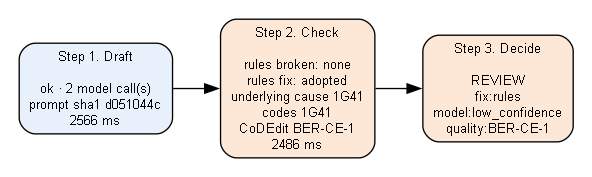

In [25]:
result = certify_record(record, deps)
print("route:", result.route.value, "| reasons:", result.reasons, "| calls:", result.usage.calls, "| timings:", result.timings_ms)
print("response keys:", sorted(as_response(result)))
print("saved only   :", sorted(set(result.model_dump()) - set(as_response(result))))
flow_diagram(result)

In [26]:
render_mccd(result)

### A record the pipeline must not certify

S22 is one of the six coroner scenarios in the dlc set: a death from carbon monoxide in a closed
garage, an external cause with a manner of death to establish, which belongs to the coroner's
pathway and not to this one. The prompt tells the model to decline such records. Expected (live
call): `assessment` is `out_of_scope`, Part I is empty, and the route is `review` with the reason
`declined:out_of_scope`. If the model certifies it anyway, the harness counts it as the wrong
action; on this model it happens on some of the six coroner cases (a tetanus after a garden injury
reads like a disease to it), which is one reason a decline is always `review` and never `auto`.


In [27]:
s22 = load_cases("dlc", ("S22",))[0]
print(s22.record.fields["case_narrative"][:400], "...")
oos = certify_record(s22.record, deps)
print()
print("assessment:", (oos.certificate or {}).get("assessment"), "| decline_reason:", (oos.certificate or {}).get("decline_reason"))
print("route     :", oos.route.value, "| reasons:", oos.reasons, "| Part I lines:", len((oos.certificate or {}).get("part1") or []))

On May 5, 2003, a 54-year-old male was found dead from carbon monoxide poisoning in an automobile in a closed garage. A hose, running into the passenger compartment of the car, was attached to the exhaust pipe. The deceased had been despondent for some time as a result of a malignancy, and letters found in the car indicated intent to take his own life. ...



assessment: out_of_scope | decline_reason: external_cause
route     : review | reasons: ['declined:out_of_scope'] | Part I lines: 0


## 7. The routes, and what a reviewer does

Two routes, and a list of reasons that is the reviewer's worklist:

| reason | what the reviewer checks |
|---|---|
| `model:low_confidence` | the model was not sure; read the note it left and the chain |
| `rule:1` to `rule:10` | a rule still breaks after the fix; the message names the line |
| `fix:rules`, `fix:terms` | the certificate was changed once; compare with the first draft in the row |
| `schema:invalid`, `model:refused`, `model:truncated`, `model:unparsable` | the model did not answer properly; rerun, or certify by hand |
| `who:line_uncoded`, `who:low_match` | a term the WHO term coder (autocode) could not match; reword it |
| `who:no_cause` | the WHO cause selector (DORIS) found no underlying cause; the chain is implausible |
| `quality:FER-CE-931` | the underlying cause is ill-defined; find the disease behind it |
| `quality:<other id>` | another WHO quality check (CoDEdit); look the id up in the CoDEdit documentation |
| `declined:out_of_scope`, `declined:insufficient` | the model declined; confirm, or send the record to the right pathway |
| `record:demographics_missing` | the record had no sex or age; add them and rerun |
| `who:unavailable`, `who:error` | the WHO container failed; rerun when it is back |

A certificate routed `auto` has none of these. In a registry system it would be accepted as
written; in this project it is still a proposal, because the client decides what `auto` is allowed
to mean.


## 8. How we measure

You cannot read a hundred certificates and know whether the pipeline is good. The mini harness in
`eval.py` runs it on the 17 provided scenarios that have reference certificates and reports the
share of first drafts that pass the rules, the share after the fix, the share routed `auto`, and
the share whose underlying cause (UCOD) code equals the reference's. The last one is the honest
measure of whether the model understood the medicine; the first is the honest measure of whether it
followed the rules.

The 40 dlc cases are scored on behaviour. Each case says what the pipeline is expected to do
(certify, decline, either) and what it must never do (certify a coroner's death, quote the wrong
patient's page, certify a negated diagnosis). The `right_action` share and the `forbidden_outcomes`
count must be right before anyone talks about accuracy.

The cell scores S01 alone through the harness so you can see one row. The how-to guide runs the
whole set and draws the charts.


In [28]:
from automccd_lite.eval import run
res = run("provided", only=("S01",), deps=deps, quiet=True)
row = res["rows"][0]
show_json(row, keys=["id", "route", "reasons", "first_try", "broken_rules", "rules_fixed", "terms_fixed",
                     "model_chain", "reference_chain", "cause", "reference_cause_code", "cause_match", "right_action"])

{
  "id": "S01-clean",
  "route": "review",
  "reasons": [
    "model:low_confidence",
    "quality:BER-CE-1"
  ],
  "first_try": {
    "schema_ok": true,
    "rules_passed": true,
    "broken_rules": []
  },
  "broken_rules": [],
  "rules_fixed": false,
  "terms_fixed": null,
  "model_chain": [
    "Staphylococcus aureus meningitis",
    "Septic shock"
  ],
  "reference_chain": [
    "Septic shock",
    "Staphylococcus aureus sepsis",
    "Staphylococcus aureus meningitis"
  ],
  "cause": "1G41",
  "reference_cause_code": "1B54",
  "cause_match": "different",
  "right_action": true
}


## Where to go from here

- Read `pipeline.py` now. It is short, and every line should be familiar.
- Change something and watch the numbers: a rule in `rules.py`, the prompt, the model.
- When your own PoC disagrees with this one, run both on S01 and compare step by step with the
  functions you used here. The difference will be in one step, and now you know which function to
  call to find it.
